https://judge.nitro-ai.org/competitions/nitro-2025/nitro-nlp/3/view

# setup + imports

In [1]:
%pip install numpy pandas pillow matplotlib torch torchvision scikit-learn 

Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install torchvision

Note: you may need to restart the kernel to use updated packages.


In [3]:
import os
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches

In [4]:
import torch
import torch.nn as nn
import torchvision
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

if torch.cuda.is_available():
    device = 'cuda'                  
elif torch.backends.mps.is_available():
    device = 'mps'                   
else:
     device = 'cpu'
print(device)

mps


In [6]:
path = "find-duck"
TRAIN_DIR = os.path.join(path, 'train_dataset')
TEST_DIR = os.path.join(path, 'test_dataset')
labels = pd.read_csv('train_data.csv')

In [7]:
def load_image(folder, id):
  img = Image.open(os.path.join(folder, str(id) + '.png')).convert('RGB')
  return np.array(img)

def get_box(id):
  box = labels[labels['DatapointID'] == id]['BoundingBox'].iloc[0]
  return [int(v) for v in box.split(' ')]

print(len(labels), 'train images | share with a duck:', round(labels['DuckOrNoDuck'].mean(), 2))
print(labels['PixelCount'].describe())

1828 train images | share with a duck: 0.81
count    1828.000000
mean     1942.892779
std      1536.015490
min         0.000000
25%      1063.750000
50%      1596.500000
75%      2839.500000
max      8826.000000
Name: PixelCount, dtype: float64


# data exploration

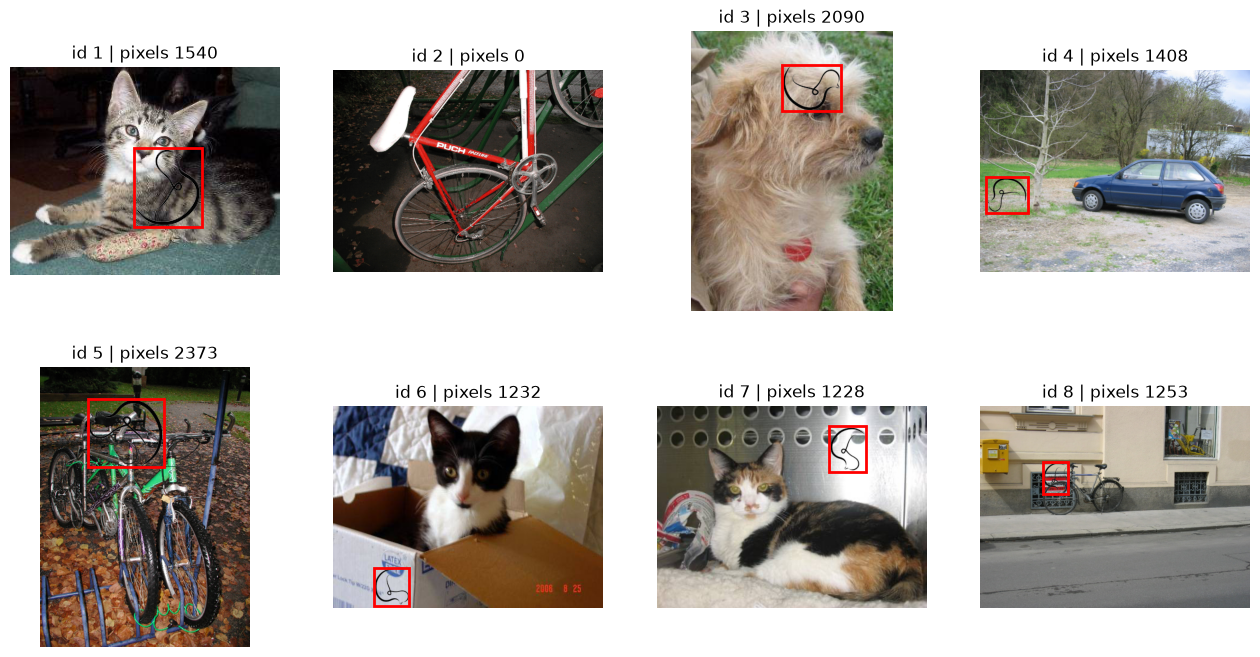

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, id in zip(axes.flat, labels['DatapointID'].head(8)):
  row = labels[labels['DatapointID'] == id].iloc[0]
  ax.imshow(load_image(TRAIN_DIR, id))
  if row['DuckOrNoDuck'] == 1:
    x1, y1, x2, y2 = get_box(id)
    ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor='red', linewidth=2))
  ax.set_title(f"id {id} | pixels {row['PixelCount']}")
  ax.axis('off')
plt.show()

In [9]:
ducks = labels[labels['DuckOrNoDuck'] == 1]
fill = []
for image_id in ducks['DatapointID']:
  x1, y1, x2, y2 = get_box(image_id)
  box_area = (x2 - x1 + 1) * (y2 - y1 + 1)
  pixel_count = ducks[ducks['DatapointID'] == image_id]['PixelCount'].iloc[0]
  fill.append(pixel_count / box_area)
FILL = np.median(fill)
print('share of the box filled by the duck | median:', round(FILL, 3), '| middle 80%:', np.round(np.percentile(fill, [10, 90]), 3))

share of the box filled by the duck | median: 0.221 | middle 80%: [0.183 0.268]


# preparing the data

In [10]:
SIZE = 384
to_input = transforms.Compose([
  transforms.Resize((SIZE, SIZE)),
  transforms.ToTensor(),
  transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

In [11]:
def imgsize(folder, id):
  return Image.open(os.path.join(folder, str(id) + '.png')).size

In [12]:
class DuckDataset(Dataset):
  def __init__(self, folder, ids, labels=None, flip=False):
    self.folder = folder
    self.ids = list(ids)
    self.labels = labels
    self.flip = flip

  def __len__(self):
    return len(self.ids)

  def __getitem__(self, i):
    id = self.ids[i]
    img = Image.open(os.path.join(self.folder, str(id) + '.png')).convert('RGB')
    width, height = img.size
    x = to_input(img)

    if self.labels is None:
      return x, id

    row = self.labels[self.labels['DatapointID'] == id].iloc[0]
    duck = torch.tensor(float(row['DuckOrNoDuck']))
    x1, y1, x2, y2 = get_box(id)
    box = torch.tensor([x1/(width-1), y1/(height-1), x2/(width-1), y2/(height-1)], dtype=torch.float32)

    if row['DuckOrNoDuck'] == 1:
        fill = row['PixelCount']/((x2-x1+1)*(y2-y1+1))
    else:
        fill = 0.0
    fill = torch.tensor(float(fill))

    if self.flip:
      k = int(torch.randint(0, 4, (1,)))           
      for _ in range(k):
        x = torch.rot90(x, 1, dims=[1, 2])
        box = torch.tensor([box[1], 1 - box[2], box[3], 1 - box[0]])
      if torch.rand(1).item() < 0.5:
        x = torch.flip(x, dims=[2])
        box = torch.tensor([1 - box[2], box[1], 1 - box[0], box[3]])
    return x, duck, box, fill

# validare

In [13]:
fit_ids, val_ids = train_test_split(list(labels['DatapointID']),
                                    test_size=0.15,
                                    random_state=0,
                                    stratify=labels['DuckOrNoDuck'])

fit_loader = DataLoader(DuckDataset(TRAIN_DIR, fit_ids, labels, flip=True),
                        batch_size=32, shuffle=True, num_workers=0)

val_loader = DataLoader(DuckDataset(TRAIN_DIR, val_ids, labels),
                        batch_size=32, shuffle=False, num_workers=0)

In [14]:
import torch
import torchvision

model = torchvision.models.resnet34(weights='DEFAULT')
model.avgpool = nn.Sequential(nn.Conv2d(512, 32, kernel_size=1), nn.ReLU())   
model.fc = nn.Linear(32 * (SIZE // 32) * (SIZE // 32), 6)
model = model.to(device)

bce = nn.BCEWithLogitsLoss()
l1 = nn.L1Loss()

In [15]:
from torchvision.ops import generalized_box_iou_loss

def compute_loss(out, duck, box, fill):
  duck_loss = bce(out[:, 0], duck)
  has_duck = duck == 1
  if has_duck.sum() == 0:
    return duck_loss
  pred_box = torch.sigmoid(out[has_duck, 1:5])
  box_loss = l1(pred_box, box[has_duck])
  overlap_loss = generalized_box_iou_loss(pred_box, box[has_duck], reduction='mean')
  fill_loss = l1(torch.sigmoid(out[has_duck, 5]), fill[has_duck])
  return duck_loss + 5*box_loss + overlap_loss + 10*fill_loss

In [16]:
def predict(model, loader):
  model.eval()
  probs = []
  boxes = []
  fills = []
  with torch.no_grad():
    for batch in loader:
        x = batch[0].to(device)
        out = model(x)
        out_m = model(torch.flip(x, dims=[3]))          
        b = torch.sigmoid(out[:, 1:5])
        bm = torch.sigmoid(out_m[:, 1:5])
        bm = torch.stack([1 - bm[:, 2], bm[:, 1], 1 - bm[:, 0], bm[:, 3]], dim=1)   
        probs.append(((torch.sigmoid(out[:, 0]) + torch.sigmoid(out_m[:, 0])) / 2).cpu().numpy())
        boxes.append(((b + bm) / 2).cpu().numpy())
        fills.append(((torch.sigmoid(out[:, 5]) + torch.sigmoid(out_m[:, 5])) / 2).cpu().numpy())
  return np.concatenate(probs), np.concatenate(boxes), np.concatenate(fills)

In [17]:
def to_pixels(box, width, height):
  xa = int(round(box[0] * (width-1)))
  ya = int(round(box[1] * (height-1)))
  xb = int(round(box[2] * (width-1)))
  yb = int(round(box[3] * (height-1)))
  return min(xa, xb), min(ya, yb), max(xa, xb), max(ya, yb)

In [18]:
def iou(a, b):
  ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])
  ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])
  inter = max(0, ix2 - ix1 + 1) * max(0, iy2 - iy1 + 1)
  area_a = (a[2]-a[0]+1) * (a[3]-a[1]+1)
  area_b = (b[2]-b[0]+1) * (b[3]-b[1]+1)
  return inter/(area_a+area_b-inter)

In [19]:
def evaluate(model, loader, ids):
  probs, boxes, fills = predict(model, loader)
  correct = 0
  ious = []
  count_errors = []
  count_errors_fixed = []
  for i, id in enumerate(ids):
    row = labels[labels['DatapointID'] == id].iloc[0]
    correct += int(int(probs[i] > 0.5) == row['DuckOrNoDuck'])
    if row['DuckOrNoDuck'] == 1:
      width, height = imgsize(TRAIN_DIR, id)
      pred = to_pixels(boxes[i], width, height)
      ious.append(iou(pred, get_box(id)))
      area = (pred[2]-pred[0]+1) * (pred[3]-pred[1]+1)
      count_errors.append(abs(fills[i] * area - row['PixelCount']))
      count_errors_fixed.append(abs(FILL * area - row['PixelCount']))
  return correct/len(ids), np.mean(ious), np.mean(count_errors), np.mean(count_errors_fixed)

# training

In [20]:
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.3, patience=2)

best_score = -1
best_weights = None
patience = 4
epochs_without_gain = 0

In [21]:
import copy

for epoch in range(40):
  model.train()
  total = 0
  for x, duck, box, fill in fit_loader:
    x, duck, box, fill = x.to(device), duck.to(device), box.to(device), fill.to(device)
    loss = compute_loss(model(x), duck, box, fill)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    total += loss.item() * len(x)

  acc, box_iou, count_err, count_err_fixed = evaluate(model, val_loader, val_ids)
  score = 20*acc + 45*box_iou
  scheduler.step(score)
  print('epoch', epoch+1, '| fit loss', round(total/len(fit_ids), 4),
        '| accuracy', round(acc, 3), '| box overlap', round(box_iou, 3),
        '| pixel error', int(count_err), '(fixed share:', int(count_err_fixed), ')')

  if score > best_score:
    best_score = score
    best_weights = copy.deepcopy(model.state_dict())
    epochs_without_gain = 0
  else:
    epochs_without_gain += 1
    if epochs_without_gain == patience:
      print('no new best for', patience, 'epochs, stopping')
      break

model.load_state_dict(best_weights)

epoch 1 | fit loss 2.7156 | accuracy 0.815 | box overlap 0.387 | pixel error 2523 (fixed share: 3514 )
epoch 2 | fit loss 1.5213 | accuracy 0.975 | box overlap 0.54 | pixel error 1248 (fixed share: 1520 )
epoch 3 | fit loss 1.0887 | accuracy 0.993 | box overlap 0.627 | pixel error 854 (fixed share: 917 )
epoch 4 | fit loss 0.9019 | accuracy 0.993 | box overlap 0.622 | pixel error 801 (fixed share: 966 )
epoch 5 | fit loss 0.7928 | accuracy 0.993 | box overlap 0.669 | pixel error 505 (fixed share: 497 )
epoch 6 | fit loss 0.733 | accuracy 0.996 | box overlap 0.64 | pixel error 480 (fixed share: 543 )
epoch 7 | fit loss 0.6531 | accuracy 0.989 | box overlap 0.7 | pixel error 643 (fixed share: 996 )
epoch 8 | fit loss 0.5951 | accuracy 0.996 | box overlap 0.741 | pixel error 430 (fixed share: 513 )
epoch 9 | fit loss 0.5649 | accuracy 0.996 | box overlap 0.77 | pixel error 369 (fixed share: 487 )
epoch 10 | fit loss 0.5587 | accuracy 0.996 | box overlap 0.805 | pixel error 360 (fixed shar

<All keys matched successfully>

In [23]:
torch.save(model.state_dict(), 'resnet_ducks.pt')

In [24]:
all_loader = DataLoader(DuckDataset(TRAIN_DIR, labels['DatapointID'], labels, flip=True),
                        batch_size=32, shuffle=True, num_workers=0)

model = torchvision.models.resnet34(weights='DEFAULT')
model.avgpool = nn.Sequential(nn.Conv2d(512, 32, kernel_size=1), nn.ReLU())
model.fc = nn.Linear(32 * (SIZE // 32) * (SIZE // 32), 6)
model = model.to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)

for epoch in range(16):
  model.train()
  total = 0
  for x, duck, box, fill in all_loader:
    x, duck, box, fill = x.to(device), duck.to(device), box.to(device), fill.to(device)
    loss = compute_loss(model(x), duck, box, fill)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    total += loss.item() * len(x)
  print('epoch', epoch + 1, '| loss', round(total / len(labels), 4))

torch.save(model.state_dict(), 'resnet_ducks_all.pt')

epoch 1 | loss 2.4458
epoch 2 | loss 1.3365
epoch 3 | loss 1.002
epoch 4 | loss 0.878
epoch 5 | loss 0.7475
epoch 6 | loss 0.6663
epoch 7 | loss 0.6274
epoch 8 | loss 0.5805
epoch 9 | loss 0.5419
epoch 10 | loss 0.5265
epoch 11 | loss 0.4913
epoch 12 | loss 0.4836
epoch 13 | loss 0.5554
epoch 14 | loss 0.4742
epoch 15 | loss 0.4407
epoch 16 | loss 0.4166


# preds

In [28]:
model = torchvision.models.resnet34(weights=None)      # no download needed, the saved weights replace them anyway
model.avgpool = nn.Sequential(nn.Conv2d(512, 32, kernel_size=1), nn.ReLU())
model.fc = nn.Linear(32 * (SIZE // 32) * (SIZE // 32), 6)
model.load_state_dict(torch.load('resnet_ducks.pt', map_location='cpu'))
model = model.to(device)

In [29]:
test_ids = list(range(1, len([f for f in os.listdir(TEST_DIR) if f.endswith('.png')])+1))
test_loader = DataLoader(DuckDataset(TEST_DIR, test_ids), batch_size=32, shuffle=False, num_workers=0)
probs, boxes, fills = predict(model, test_loader)

In [30]:
rows = []
for i, image_id in enumerate(test_ids):
  if probs[i] > 0.5:
    width, height = imgsize(TEST_DIR, image_id)
    x1, y1, x2, y2 = to_pixels(boxes[i], width, height)
    count = int(round(fills[i] * (x2 - x1 + 1) * (y2 - y1 + 1)))
    rows.append([1, image_id, '1'])
    rows.append([2, image_id, str(count)])
    rows.append([3, image_id, str(x1) + ' ' + str(y1) + ' ' + str(x2) + ' ' + str(y2)])
  else:
    rows.append([1, image_id, '0'])
    rows.append([2, image_id, '0'])
    rows.append([3, image_id, '0 0 0 0'])

In [31]:
submission = pd.DataFrame(rows, columns=['subtaskID', 'datapointID', 'answer'])
submission = submission.sort_values(['subtaskID', 'datapointID'])
submission.to_csv('output.csv', index=False)
print(submission.shape)

(1500, 3)
